# Adaboost demo

In [2]:
import numpy as np 
import pandas as pd 
from mlxtend.plotting import plot_decision_regions

In [3]:
df= pd.DataFrame()

In [5]:
df['X1'] = [1,2,3,4,5,6,7,8,9,9]
df['X2'] = [5,3,6,8,1,9,5,8,9,2]
df['label'] = [1,1,0,1,0,1,0,1,0,0]

In [6]:
df

,X1,X2,label
0,1,5,1
1,2,3,1
2,3,6,0
3,4,8,1
4,5,1,0
5,6,9,1
6,7,5,0
7,8,8,1
8,9,9,0
9,9,2,0


<Axes: xlabel='X1', ylabel='X2'>

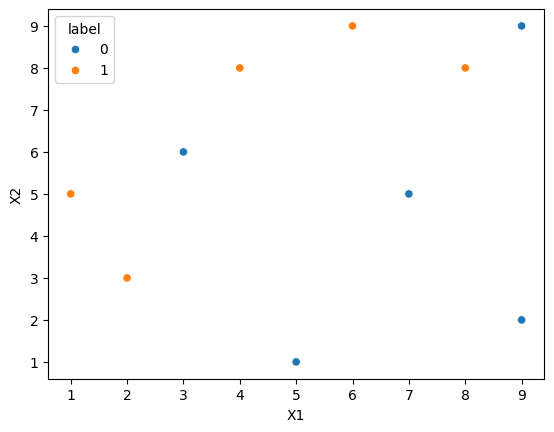

In [8]:
import seaborn as sns
sns.scatterplot(x=df['X1'], y=df['X2'], hue=df['label'])

In [10]:
df['Weights'] = 1/df.shape[0]
df

,X1,X2,label,Weights
0,1,5,1,0.1
1,2,3,1,0.1
2,3,6,0,0.1
3,4,8,1,0.1
4,5,1,0,0.1
5,6,9,1,0.1
6,7,5,0,0.1
7,8,8,1,0.1
8,9,9,0,0.1
9,9,2,0,0.1


In [11]:
from sklearn.tree import DecisionTreeClassifier
dt1 = DecisionTreeClassifier(max_depth=1)

In [12]:
X = df.iloc[:, 0:2].values
y = df.iloc[:, 2].values

In [13]:
# Step 2 : Train 1st model

dt1.fit(X,y)


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples a

[Text(0.5, 0.75, 'x[1] <= 2.5\ngini = 0.5\nsamples = 10\nvalue = [5, 5]'),
 Text(0.25, 0.25, 'gini = 0.0\nsamples = 2\nvalue = [2, 0]'),
 Text(0.375, 0.5, 'True  '),
 Text(0.75, 0.25, 'gini = 0.469\nsamples = 8\nvalue = [3, 5]'),
 Text(0.625, 0.5, '  False')]

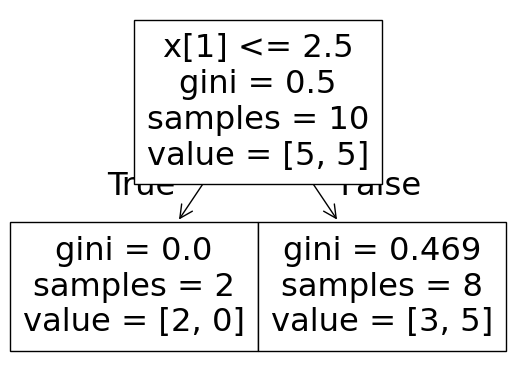

In [14]:
from sklearn.tree import plot_tree
plot_tree(dt1)

<Axes: >

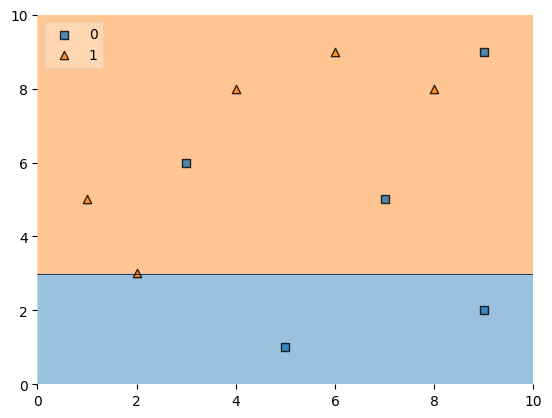

In [15]:
plot_decision_regions(X,y, clf=dt1, legend=2)

In [17]:
df['y_pred'] = dt1.predict(X)
df

,X1,X2,label,Weights,y_pred
0,1,5,1,0.1,1
1,2,3,1,0.1,1
2,3,6,0,0.1,1
3,4,8,1,0.1,1
4,5,1,0,0.1,0
5,6,9,1,0.1,1
6,7,5,0,0.1,1
7,8,8,1,0.1,1
8,9,9,0,0.1,1
9,9,2,0,0.1,0


In [ ]:
def calculate_model_weight(error):
    return 0.5 * np.log((1-error)/(error))


In [19]:
# Step 3 - calculate model weight
alpha1 = calculate_model_weight(0.3)
alpha1

np.float64(0.42364893019360184)

In [26]:
# Step 4 - Update weights of the samples

def update_row_weights(row, alpha=0.423):
    if row['label'] == row['y_pred']:
        return row['Weights'] * np.exp(-alpha)
    else:
        return row['Weights'] * np.exp(alpha)

In [28]:
df['updated_Weights'] = df.apply(update_row_weights, axis=1)
df


,X1,X2,label,Weights,y_pred,updated_Weights
0,1,5,1,0.1,1,0.065508
1,2,3,1,0.1,1,0.065508
2,3,6,0,0.1,1,0.152653
3,4,8,1,0.1,1,0.065508
4,5,1,0,0.1,0,0.065508
5,6,9,1,0.1,1,0.065508
6,7,5,0,0.1,1,0.152653
7,8,8,1,0.1,1,0.065508
8,9,9,0,0.1,1,0.152653
9,9,2,0,0.1,0,0.065508


In [29]:
df['updated_Weights'].sum()

np.float64(0.9165153319682015)

In [31]:
df['normalized_weights'] = df['updated_Weights'] / df['updated_Weights'].sum()

df

,X1,X2,label,Weights,y_pred,updated_Weights,normalized_weights
0,1,5,1,0.1,1,0.065508,0.071475
1,2,3,1,0.1,1,0.065508,0.071475
2,3,6,0,0.1,1,0.152653,0.166559
3,4,8,1,0.1,1,0.065508,0.071475
4,5,1,0,0.1,0,0.065508,0.071475
5,6,9,1,0.1,1,0.065508,0.071475
6,7,5,0,0.1,1,0.152653,0.166559
7,8,8,1,0.1,1,0.065508,0.071475
8,9,9,0,0.1,1,0.152653,0.166559
9,9,2,0,0.1,0,0.065508,0.071475


In [33]:
df['normalized_weights'].sum()

np.float64(1.0)

In [38]:
df['cumsum_upper'] = np.cumsum(df['normalized_weights'])
df['cumsum_lower'] = df['cumsum_upper'] - df['normalized_weights']
df

,X1,X2,label,Weights,y_pred,updated_Weights,normalized_weights,cumsum_upper,cumsum_lower
0,1,5,1,0.1,1,0.065508,0.071475,0.071475,0.000000
1,2,3,1,0.1,1,0.065508,0.071475,0.142950,0.071475
2,3,6,0,0.1,1,0.152653,0.166559,0.309508,0.142950
3,4,8,1,0.1,1,0.065508,0.071475,0.380983,0.309508
4,5,1,0,0.1,0,0.065508,0.071475,0.452458,0.380983
5,6,9,1,0.1,1,0.065508,0.071475,0.523933,0.452458
6,7,5,0,0.1,1,0.152653,0.166559,0.690492,0.523933
7,8,8,1,0.1,1,0.065508,0.071475,0.761967,0.690492
8,9,9,0,0.1,1,0.152653,0.166559,0.928525,0.761967
9,9,2,0,0.1,0,0.065508,0.071475,1.000000,0.928525


In [40]:
def create_new_dataset(df):

    indices = []

    for i in range(df.shape[0]):
        a = np.random.random()
        for index, row in df.iterrows():
            if row['cumsum_upper'] > a and a > row['cumsum_lower']:
                indices.append(index)
    return indices


In [41]:
index_values = create_new_dataset(df)
index_values

[2, 7, 4, 1, 1, 3, 8, 2, 9, 8]

In [42]:
second_df = df.iloc[index_values, [0,1,2,3]]
second_df

,X1,X2,label,Weights
2,3,6,0,0.1
7,8,8,1,0.1
4,5,1,0,0.1
1,2,3,1,0.1
1,2,3,1,0.1
3,4,8,1,0.1
8,9,9,0,0.1
2,3,6,0,0.1
9,9,2,0,0.1
8,9,9,0,0.1


In [43]:
dt2 = DecisionTreeClassifier(max_depth=1)

In [44]:
X = second_df.iloc[:, 0:2].values
y = second_df.iloc[:,2].values

In [45]:
dt2.fit(X,y)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples a

[Text(0.5, 0.75, 'x[0] <= 2.5\ngini = 0.48\nsamples = 10\nvalue = [6, 4]'),
 Text(0.25, 0.25, 'gini = 0.0\nsamples = 2\nvalue = [0, 2]'),
 Text(0.375, 0.5, 'True  '),
 Text(0.75, 0.25, 'gini = 0.375\nsamples = 8\nvalue = [6, 2]'),
 Text(0.625, 0.5, '  False')]

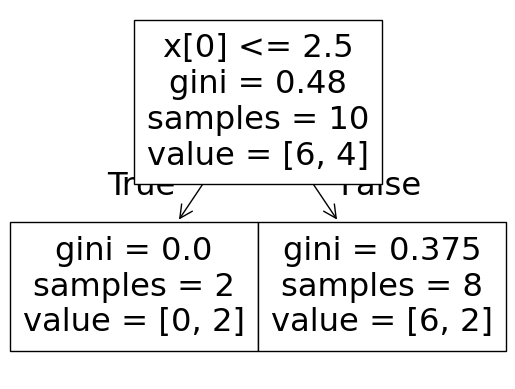

In [46]:
plot_tree(dt2)

<Axes: >

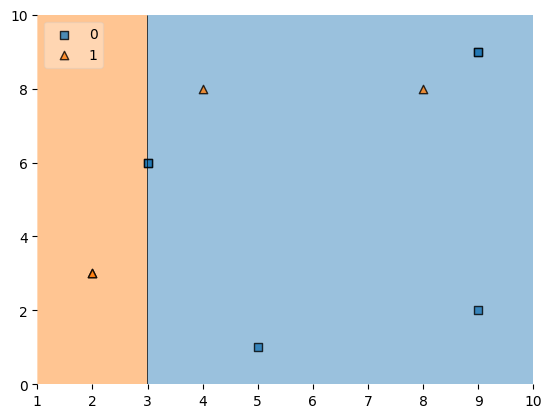

In [47]:
plot_decision_regions(X,y, clf=dt2, legend=2)

In [49]:
second_df['y_pred'] = dt2.predict(X)
second_df

,X1,X2,label,Weights,y_pred
2,3,6,0,0.1,0
7,8,8,1,0.1,0
4,5,1,0,0.1,0
1,2,3,1,0.1,1
1,2,3,1,0.1,1
3,4,8,1,0.1,0
8,9,9,0,0.1,0
2,3,6,0,0.1,0
9,9,2,0,0.1,0
8,9,9,0,0.1,0


In [52]:
alpha2 = calculate_model_weight(0.1)
alpha2

np.float64(1.0986122886681098)

In [55]:
# Step 4 - update weights

def update_row_weights(row, alpha=1.09):
    if row['label'] == row['y_pred']:
        return row['Weights'] * np.exp(-alpha)
    else:
        return row['Weights'] * np.exp(alpha)  

In [56]:
second_df['updated_Weights'] = second_df.apply(update_row_weights, axis=1)
second_df

,X1,X2,label,Weights,y_pred,updated_Weights
2,3,6,0,0.1,0,0.033622
7,8,8,1,0.1,0,0.297427
4,5,1,0,0.1,0,0.033622
1,2,3,1,0.1,1,0.033622
1,2,3,1,0.1,1,0.033622
3,4,8,1,0.1,0,0.297427
8,9,9,0,0.1,0,0.033622
2,3,6,0,0.1,0,0.033622
9,9,2,0,0.1,0,0.033622
8,9,9,0,0.1,0,0.033622


In [57]:
second_df['normalized_Weights'] = second_df['updated_Weights'].sum()

In [59]:
second_df

,X1,X2,label,Weights,y_pred,updated_Weights,normalized_Weights
2,3,6,0,0.1,0,0.033622,0.863828
7,8,8,1,0.1,0,0.297427,0.863828
4,5,1,0,0.1,0,0.033622,0.863828
1,2,3,1,0.1,1,0.033622,0.863828
1,2,3,1,0.1,1,0.033622,0.863828
3,4,8,1,0.1,0,0.297427,0.863828
8,9,9,0,0.1,0,0.033622,0.863828
2,3,6,0,0.1,0,0.033622,0.863828
9,9,2,0,0.1,0,0.033622,0.863828
8,9,9,0,0.1,0,0.033622,0.863828


In [60]:
second_df['normalized_Weights'].sum()

np.float64(8.638280094779999)

In [62]:
second_df['cumsum_upper'] = np.cumsum(second_df['normalized_Weights'])
second_df['cumsum_lower'] = second_df['cumsum_upper'] - second_df['normalized_Weights']

In [63]:
second_df[['X1', 'X2', 'label', 'Weights', 'y_pred', 'updated_Weights', 'normalized_Weights', 'cumsum_upper', 'cumsum_lower']]

,X1,X2,label,Weights,y_pred,updated_Weights,normalized_Weights,cumsum_upper,cumsum_lower
2,3,6,0,0.1,0,0.033622,0.863828,0.863828,0.000000
7,8,8,1,0.1,0,0.297427,0.863828,1.727656,0.863828
4,5,1,0,0.1,0,0.033622,0.863828,2.591484,1.727656
1,2,3,1,0.1,1,0.033622,0.863828,3.455312,2.591484
1,2,3,1,0.1,1,0.033622,0.863828,4.319140,3.455312
3,4,8,1,0.1,0,0.297427,0.863828,5.182968,4.319140
8,9,9,0,0.1,0,0.033622,0.863828,6.046796,5.182968
2,3,6,0,0.1,0,0.033622,0.863828,6.910624,6.046796
9,9,2,0,0.1,0,0.033622,0.863828,7.774452,6.910624
8,9,9,0,0.1,0,0.033622,0.863828,8.638280,7.774452


In [64]:
index_values = create_new_dataset(second_df)

In [66]:
third_df = second_df.iloc[index_values, [0,1,2,3]]
third_df

,X1,X2,label,Weights
4,5,1,0,0.1
4,5,1,0,0.1
4,5,1,0,0.1
4,5,1,0,0.1
2,3,6,0,0.1
4,5,1,0,0.1
4,5,1,0,0.1
4,5,1,0,0.1
4,5,1,0,0.1
4,5,1,0,0.1


In [67]:
dt3 = DecisionTreeClassifier(max_depth=1)

In [68]:
X = second_df.iloc[:, 0:2].values
y = second_df.iloc[:, 2].values

dt3.fit(X,y)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples a

<Axes: >

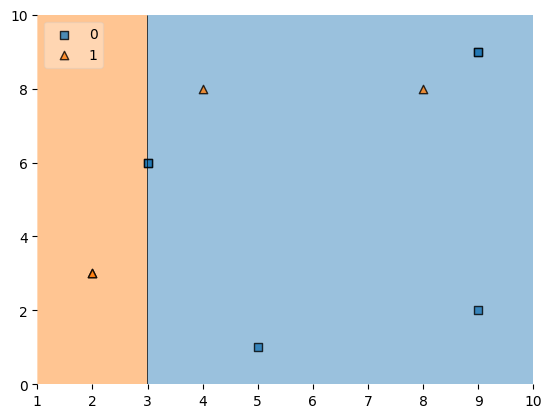

In [69]:
plot_decision_regions(X, y, clf=dt3, legend=2)

In [71]:
third_df['y_pred'] = dt3.predict(X)
third_df

,X1,X2,label,Weights,y_pred
4,5,1,0,0.1,0
4,5,1,0,0.1,0
4,5,1,0,0.1,0
4,5,1,0,0.1,1
2,3,6,0,0.1,1
4,5,1,0,0.1,0
4,5,1,0,0.1,0
4,5,1,0,0.1,0
4,5,1,0,0.1,0
4,5,1,0,0.1,0


In [72]:
alpha3 = calculate_model_weight(0.7)
alpha3

np.float64(-0.4236489301936017)

In [73]:
print(alpha1, alpha2, alpha3)

0.42364893019360184 1.0986122886681098 -0.4236489301936017


# Prediction

In [ ]:
query = np.array([1,5]).reshape(1,2)
dt1.predict(query)


array([1])

In [77]:
dt2.predict(query)

array([1])

In [78]:
dt3.predict(query)

array([1])

In [79]:
alpha1*1 + alpha2*(1) + alpha3*(1)

np.float64(1.09861228866811)

In [81]:
np.sign(1.09)

np.float64(1.0)

In [82]:
query = np.array([9,9]).reshape(1,2)
dt1.predict(query)

array([1])

In [83]:
dt2.predict(query)

array([0])

In [84]:
dt3.predict(query)

array([0])

In [85]:
alpha1 *(-1) + alpha2*(-1) + alpha3*(-1)

np.float64(-1.09861228866811)

In [87]:
np.sign(-0.25)

np.float64(-1.0)

In [88]:
alpha3 = calculate_model_weight(0.7)
alpha3

np.float64(-0.4236489301936017)

In [89]:
print(alpha1, alpha2, alpha3)

0.42364893019360184 1.0986122886681098 -0.4236489301936017
